# cfDNA fragment subsampling and baseline comparisons (Supplementary Figures 7,9-13)

Figures produced:

- Supplementary Figure 7 (`cfdna_kmer_lm_delta_auc`): LEAF-1 AUC advantage (ΔAUC, LEAF-1 − baseline) over the 14 cfDNA tasks, versus canonical k-mer baselines (panel a) and external DNA language models (panel b), with BCa 95% CIs and per-task jitter.
- Supplementary Figure 9 (`cfdna_emb_vs_binonly`): embedding versus Bin-only AUC at 100,000 fragments, by bin resolution.
- Supplementary Figure 10 (`cfdna_emb_vs_binlength`): embedding versus Bin+Length.
- Supplementary Figure 11 (`cfdna_emb_vs_bindelfi`): embedding versus Bin+DELFI.
- Supplementary Figure 12 (`cfdna_subsampling_vs_healthy`): per-cancer cancer-vs-healthy AUC against fragment count.
- Supplementary Figure 13 (`cfdna_subsampling_vs_other`): per-cancer cancer-vs-other-cancers AUC against fragment count.

The subsampling curves use the 300 kb (10,000-bin) resolution for the binning baselines.
Reads `../data/cfdna_delta_auc_summary.csv`, `../data/cfdna_delta_auc_per_task.csv`, and
`../data/cfdna_fragment_subsampling_auc.csv`; writes figures to `../output/`.
Sources: `dna-embedding-benchmark/benchmark/notebook/{combined_only_benchmark_leaf_external, combined_only_benchmark_leaf_kmer}.ipynb` (Supp 7);
`mil/mil_nested/cfdna_visualization/supp_cfdna_subsampling.ipynb` (Supp 9-13).


In [1]:
from pathlib import Path
import sys

# Self-contained: works when run from this notebook's folder (nbconvert default),
# from the modality folder, or from the repo root.
nb_dir = Path.cwd()
if (nb_dir / "data").exists() and (nb_dir / "output").exists():
    MOD_DIR = nb_dir
elif (nb_dir.parent / "data").exists():
    MOD_DIR = nb_dir.parent
else:
    MOD_DIR = nb_dir
DATA = MOD_DIR / "data"
OUT = MOD_DIR / "output"
OUT.mkdir(exist_ok=True)

# Locate the shared style helper (src/leaf1figures) by walking up.
_p = nb_dir
while _p != _p.parent and not (_p / "src" / "leaf1figures").exists():
    _p = _p.parent
sys.path.insert(0, str(_p / "src"))

from leaf1figures.style import OKABE_ITO, savefig, set_paper_style
set_paper_style()
print("DATA:", DATA)
print("OUT :", OUT)


DATA: /home/jingz/leaf-1-figures/cfdna/data
OUT : /home/jingz/leaf-1-figures/cfdna/output


saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_kmer_lm_delta_auc.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_kmer_lm_delta_auc.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_kmer_lm_delta_auc.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_kmer_lm_delta_auc.tsv


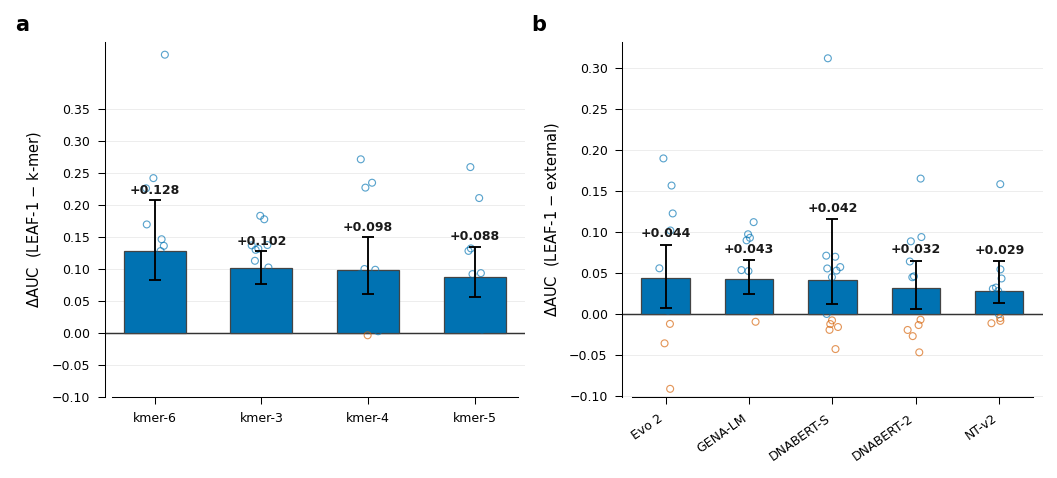

In [2]:
# =============================================================================
# SUPP FIG 7: LEAF-1 AUC advantage over k-mer (a) and external DNA LM (b) baselines
# Bar = mean delta-AUC (LEAF-1 - baseline) over 14 cfDNA tasks, BCa 95% CI;
# open circles = per-task delta. Source: combined_only_benchmark_leaf_{kmer,external}.ipynb
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

summary = pd.read_csv(DATA / 'cfdna_delta_auc_summary.csv')
per_task = pd.read_csv(DATA / 'cfdna_delta_auc_per_task.csv')

LEAF_BLUE = OKABE_ITO['blue']
LEAF_ORNG = OKABE_ITO['orange']
BAR_EDGE = '#444444'
ERR_COL = '#1A1A1A'
GRID_YS = [-0.10, -0.05, 0.00, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.35]


def draw_panel(ax, comparison, ylabel, rotate_xticks):
    s = summary[summary['comparison'] == comparison].sort_values(
        'mean_delta', ascending=False).reset_index(drop=True)
    order = s['baseline'].tolist()
    x = np.arange(len(order))
    deltas = s['mean_delta'].values
    lo = s['mean_delta_lo'].values
    hi = s['mean_delta_hi'].values
    err_lo = deltas - lo
    err_hi = hi - deltas
    # Blue when 95% CI excludes 0 (LEAF-1 significantly better); orange otherwise.
    bar_colors = [LEAF_BLUE if l > 0 else LEAF_ORNG for l in lo]

    for yt in GRID_YS:
        ax.axhline(yt, color='#EAEAEA', lw=0.4, zorder=0)
    ax.axhline(0, color='#333333', linewidth=0.7, zorder=1)

    ax.bar(x, deltas, width=0.58, color=bar_colors, edgecolor=BAR_EDGE,
           linewidth=0.6, zorder=2, yerr=[err_lo, err_hi], capsize=3,
           error_kw={'linewidth': 0.9, 'capthick': 0.9, 'color': ERR_COL, 'zorder': 4})

    # Per-task jitter (open circles, colored by sign).
    rng = np.random.default_rng(42)
    all_d = []
    for i, base in enumerate(order):
        d = per_task[(per_task['comparison'] == comparison) &
                     (per_task['baseline'] == base)]['delta'].values
        all_d.extend(d.tolist())
        jitter = rng.uniform(-0.10, 0.10, size=len(d))
        pt_colors = [LEAF_BLUE if v >= 0 else LEAF_ORNG for v in d]
        ax.scatter(np.full(len(d), i) + jitter, d, facecolors='none',
                   edgecolors=pt_colors, linewidth=0.55, alpha=0.65, s=11, zorder=3)

    for i, (d, h) in enumerate(zip(deltas, err_hi)):
        ax.text(i, d + h + 0.006, f'{d:+.3f}', ha='center', va='bottom',
                fontsize=6, fontweight='bold', color='#1A1A1A')

    ax.set_ylabel(ylabel)
    ax.set_xticks(x)
    disp = s['baseline_display'].tolist()
    if rotate_xticks:
        ax.set_xticklabels(disp, rotation=35, ha='right')
    else:
        ax.set_xticklabels(disp)

    all_d = np.asarray(all_d, dtype=float)
    y_low = min(-0.10, float(np.nanmin(all_d)) - 0.01)
    y_high = max(0.33, float(np.nanmax(all_d)) + 0.02)
    ax.set_ylim(y_low, y_high)
    ax.set_yticks([yt for yt in GRID_YS if y_low - 1e-9 <= yt <= y_high + 1e-9])
    ax.spines['bottom'].set_bounds(x[0] - 0.4, x[-1] + 0.4)


fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.2))
draw_panel(axes[0], 'kmer', r'$\Delta$AUC  (LEAF-1 $-$ k-mer)', rotate_xticks=False)
draw_panel(axes[1], 'external', r'$\Delta$AUC  (LEAF-1 $-$ external)', rotate_xticks=True)
for ax, letter in zip(axes, 'ab'):
    ax.text(-0.18, 1.02, letter, transform=ax.transAxes,
            fontsize=10, fontweight='bold', va='bottom', ha='right')

plt.tight_layout()
savefig(fig, OUT, 'cfdna_kmer_lm_delta_auc',
        data=summary[['comparison', 'baseline_display', 'mean_delta',
                      'mean_delta_lo', 'mean_delta_hi', 'n', 'wins', 'losses']])


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# rcParams matching the source supplementary subsampling notebook.
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['DejaVu Sans', 'Liberation Sans', 'Arial', 'Helvetica'],
    'font.size': 6,
    'axes.titlesize': 7,
    'axes.labelsize': 7,
    'xtick.labelsize': 6,
    'ytick.labelsize': 6,
    'legend.fontsize': 5,
    'axes.linewidth': 0.5,
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'figure.dpi': 150,
    'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'pdf.fonttype': 42,
})

# Color / label / order conventions (from source notebook).
CONFIG_COLORS = {
    'Embedding (mod_fragment1)': OKABE_ITO['blue'],     # #0072B2
    'Binning (Bin + Length)':    OKABE_ITO['orange'],   # #D55E00
    'Binning (Bin + DELFI)':     OKABE_ITO['green'],    # #009E73
    'Binning (Bin Only)':        '#CC79A7',             # pink
}
CONFIG_LABELS = {
    'Embedding (mod_fragment1)': 'Embedding',
    'Binning (Bin + Length)':    'Bin + Length',
    'Binning (Bin + DELFI)':     'Bin + DELFI',
    'Binning (Bin Only)':        'Bin only',
}
CONFIG_ORDER = ['Embedding (mod_fragment1)', 'Binning (Bin + Length)',
                'Binning (Bin + DELFI)', 'Binning (Bin Only)']

CANCERS = ['Bile_duct', 'Breast', 'Colorectal', 'Gastric', 'Lung', 'Ovarian', 'Pancreatic']
CANCER_LABELS = ['Bile duct', 'Breast', 'Colorectal', 'Gastric', 'Lung', 'Ovarian', 'Pancreatic']

# n_bins used for binning curves in S7/S8 (representative resolution from source notebook).
CURVE_NBINS = 10000.0

df_base = pd.read_csv(DATA / 'cfdna_fragment_subsampling_auc.csv')
print('Loaded:', len(df_base), 'rows')
print('Configs:', sorted(df_base['config'].unique()))
print('n_bins :', sorted(df_base['n_bins'].dropna().unique()))
print('Setup complete')


Loaded: 7020 rows
Configs: ['Binning (Bin + DELFI)', 'Binning (Bin + Length)', 'Binning (Bin Only)', 'Embedding (mod_fragment1)']
n_bins : [np.float64(10000.0), np.float64(30000.0), np.float64(100000.0), np.float64(300000.0)]
Setup complete


saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binonly.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binonly.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binonly.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binonly.tsv


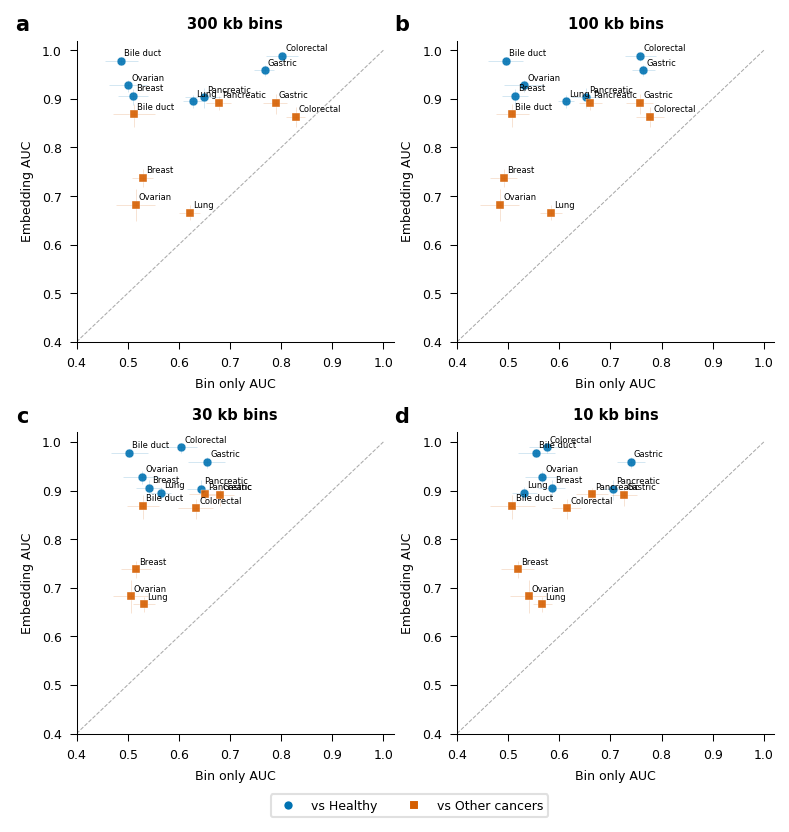

In [4]:
# =============================================================================
# SUPP FIG 9: Embedding AUC (y) vs Bin only AUC (x) at 100K fragments
# 4 panels = 4 n_bins resolutions. Blue circle = vs Healthy, orange square = vs Other.
# Error bars on both axes from ci_low/ci_high; dashed diagonal = parity.
# =============================================================================
BIN_METHOD = 'Binning (Bin Only)'
BIN_SHORT = 'Bin only'
NBINS_GRID = [10000.0, 30000.0, 100000.0, 300000.0]
NBINS_GRID_LABELS = ['300 kb bins', '100 kb bins', '30 kb bins', '10 kb bins']

legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=OKABE_ITO['blue'],
               markersize=5, label='vs Healthy'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=OKABE_ITO['orange'],
               markersize=5, label='vs Other cancers'),
]

fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2, hspace=0.3)

for panel_idx, (n_bins, nb_label) in enumerate(zip(NBINS_GRID, NBINS_GRID_LABELS)):
    ax = fig.add_subplot(gs[panel_idx // 2, panel_idx % 2])
    ax.plot([0.4, 1.0], [0.4, 1.0], color='#AAAAAA', linestyle='--',
            linewidth=0.5, zorder=1)

    for comparison, color, marker in [('vs_healthy', OKABE_ITO['blue'], 'o'),
                                      ('vs_other_cancers', OKABE_ITO['orange'], 's')]:
        emb_aucs, bin_aucs = [], []
        emb_ci_los, emb_ci_his = [], []
        bin_ci_los, bin_ci_his = [], []
        clabels = []
        for cancer, clabel in zip(CANCERS, CANCER_LABELS):
            task = f'{cancer}_cancer_{comparison}'
            emb = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == 'Embedding (mod_fragment1)') &
                          (df_base['sample_size'] == 100000)]
            bsub = df_base[(df_base['cancer'] == task) &
                           (df_base['config'] == BIN_METHOD) &
                           (df_base['n_bins'] == n_bins) &
                           (df_base['sample_size'] == 100000)]
            if emb.empty or bsub.empty:
                continue
            emb_aucs.append(emb['auc_mean'].values[0])
            emb_ci_los.append(emb['ci_low'].values[0])
            emb_ci_his.append(emb['ci_high'].values[0])
            bin_aucs.append(bsub['auc_mean'].values[0])
            bin_ci_los.append(bsub['ci_low'].values[0])
            bin_ci_his.append(bsub['ci_high'].values[0])
            clabels.append(clabel)

        emb_aucs = np.array(emb_aucs); bin_aucs = np.array(bin_aucs)
        ax.errorbar(bin_aucs, emb_aucs,
                    xerr=[bin_aucs - np.array(bin_ci_los), np.array(bin_ci_his) - bin_aucs],
                    yerr=[emb_aucs - np.array(emb_ci_los), np.array(emb_ci_his) - emb_aucs],
                    fmt='none', ecolor=color, alpha=0.2, elinewidth=0.4, zorder=2)
        ax.scatter(bin_aucs, emb_aucs, c=color, s=18, alpha=0.9, marker=marker,
                   edgecolors='white', linewidth=0.2, zorder=3)
        for ba, ea, cl in zip(bin_aucs, emb_aucs, clabels):
            ax.annotate(cl, (ba, ea), fontsize=4, ha='left', va='bottom',
                        xytext=(1.5, 1.5), textcoords='offset points')

    ax.set_xlim(0.4, 1.02)
    ax.set_ylim(0.4, 1.02)
    ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_title(nb_label, fontsize=7, fontweight='bold')
    ax.set_ylabel('Embedding AUC', fontsize=6)
    ax.set_xlabel(f'{BIN_SHORT} AUC', fontsize=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(-0.15, 1.02, 'abcd'[panel_idx], transform=ax.transAxes,
            fontsize=10, fontweight='bold', va='bottom', ha='right')

fig.axes[2].legend(handles=legend_handles, loc='upper center',
                   bbox_to_anchor=(1.05, -0.18), ncol=2, frameon=True,
                   fontsize=6, facecolor='white', edgecolor='#DDDDDD', framealpha=0.9)

savefig(fig, OUT, 'cfdna_emb_vs_binonly', data=(df_base[(df_base['config']==BIN_METHOD) & (df_base['sample_size']==100000) & (df_base['n_bins'].isin(NBINS_GRID))][['cancer','n_bins','auc_mean','ci_low','ci_high']].drop_duplicates(['cancer','n_bins']).rename(columns={'auc_mean':'bin_auc','ci_low':'bin_ci_low','ci_high':'bin_ci_high'}).merge(df_base[(df_base['config']=='Embedding (mod_fragment1)') & (df_base['sample_size']==100000)][['cancer','auc_mean','ci_low','ci_high']].drop_duplicates('cancer').rename(columns={'auc_mean':'emb_auc','ci_low':'emb_ci_low','ci_high':'emb_ci_high'}), on='cancer', how='inner')))
plt.show()

saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binlength.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binlength.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binlength.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_binlength.tsv


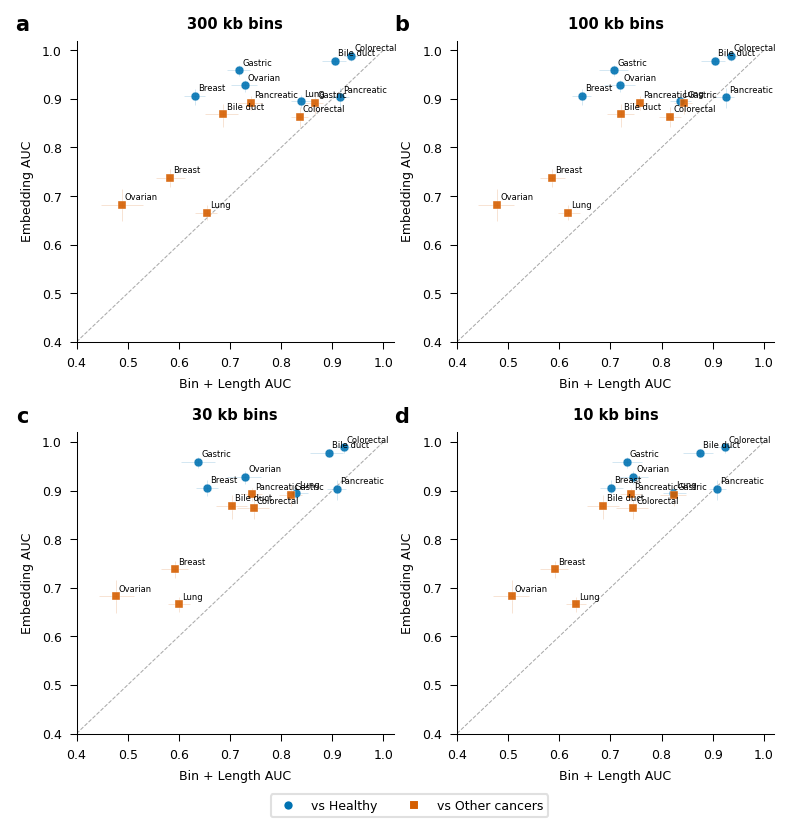

In [5]:
# =============================================================================
# SUPP FIG 10: Embedding AUC (y) vs Bin + Length AUC (x) at 100K fragments
# 4 panels = 4 n_bins resolutions. Blue circle = vs Healthy, orange square = vs Other.
# Error bars on both axes from ci_low/ci_high; dashed diagonal = parity.
# =============================================================================
BIN_METHOD = 'Binning (Bin + Length)'
BIN_SHORT = 'Bin + Length'
NBINS_GRID = [10000.0, 30000.0, 100000.0, 300000.0]
NBINS_GRID_LABELS = ['300 kb bins', '100 kb bins', '30 kb bins', '10 kb bins']

legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=OKABE_ITO['blue'],
               markersize=5, label='vs Healthy'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=OKABE_ITO['orange'],
               markersize=5, label='vs Other cancers'),
]

fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2, hspace=0.3)

for panel_idx, (n_bins, nb_label) in enumerate(zip(NBINS_GRID, NBINS_GRID_LABELS)):
    ax = fig.add_subplot(gs[panel_idx // 2, panel_idx % 2])
    ax.plot([0.4, 1.0], [0.4, 1.0], color='#AAAAAA', linestyle='--',
            linewidth=0.5, zorder=1)

    for comparison, color, marker in [('vs_healthy', OKABE_ITO['blue'], 'o'),
                                      ('vs_other_cancers', OKABE_ITO['orange'], 's')]:
        emb_aucs, bin_aucs = [], []
        emb_ci_los, emb_ci_his = [], []
        bin_ci_los, bin_ci_his = [], []
        clabels = []
        for cancer, clabel in zip(CANCERS, CANCER_LABELS):
            task = f'{cancer}_cancer_{comparison}'
            emb = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == 'Embedding (mod_fragment1)') &
                          (df_base['sample_size'] == 100000)]
            bsub = df_base[(df_base['cancer'] == task) &
                           (df_base['config'] == BIN_METHOD) &
                           (df_base['n_bins'] == n_bins) &
                           (df_base['sample_size'] == 100000)]
            if emb.empty or bsub.empty:
                continue
            emb_aucs.append(emb['auc_mean'].values[0])
            emb_ci_los.append(emb['ci_low'].values[0])
            emb_ci_his.append(emb['ci_high'].values[0])
            bin_aucs.append(bsub['auc_mean'].values[0])
            bin_ci_los.append(bsub['ci_low'].values[0])
            bin_ci_his.append(bsub['ci_high'].values[0])
            clabels.append(clabel)

        emb_aucs = np.array(emb_aucs); bin_aucs = np.array(bin_aucs)
        ax.errorbar(bin_aucs, emb_aucs,
                    xerr=[bin_aucs - np.array(bin_ci_los), np.array(bin_ci_his) - bin_aucs],
                    yerr=[emb_aucs - np.array(emb_ci_los), np.array(emb_ci_his) - emb_aucs],
                    fmt='none', ecolor=color, alpha=0.2, elinewidth=0.4, zorder=2)
        ax.scatter(bin_aucs, emb_aucs, c=color, s=18, alpha=0.9, marker=marker,
                   edgecolors='white', linewidth=0.2, zorder=3)
        for ba, ea, cl in zip(bin_aucs, emb_aucs, clabels):
            ax.annotate(cl, (ba, ea), fontsize=4, ha='left', va='bottom',
                        xytext=(1.5, 1.5), textcoords='offset points')

    ax.set_xlim(0.4, 1.02)
    ax.set_ylim(0.4, 1.02)
    ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_title(nb_label, fontsize=7, fontweight='bold')
    ax.set_ylabel('Embedding AUC', fontsize=6)
    ax.set_xlabel(f'{BIN_SHORT} AUC', fontsize=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(-0.15, 1.02, 'abcd'[panel_idx], transform=ax.transAxes,
            fontsize=10, fontweight='bold', va='bottom', ha='right')

fig.axes[2].legend(handles=legend_handles, loc='upper center',
                   bbox_to_anchor=(1.05, -0.18), ncol=2, frameon=True,
                   fontsize=6, facecolor='white', edgecolor='#DDDDDD', framealpha=0.9)

savefig(fig, OUT, 'cfdna_emb_vs_binlength', data=(df_base[(df_base['config']==BIN_METHOD) & (df_base['sample_size']==100000) & (df_base['n_bins'].isin(NBINS_GRID))][['cancer','n_bins','auc_mean','ci_low','ci_high']].drop_duplicates(['cancer','n_bins']).rename(columns={'auc_mean':'bin_auc','ci_low':'bin_ci_low','ci_high':'bin_ci_high'}).merge(df_base[(df_base['config']=='Embedding (mod_fragment1)') & (df_base['sample_size']==100000)][['cancer','auc_mean','ci_low','ci_high']].drop_duplicates('cancer').rename(columns={'auc_mean':'emb_auc','ci_low':'emb_ci_low','ci_high':'emb_ci_high'}), on='cancer', how='inner')))
plt.show()

saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_bindelfi.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_bindelfi.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_bindelfi.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_emb_vs_bindelfi.tsv


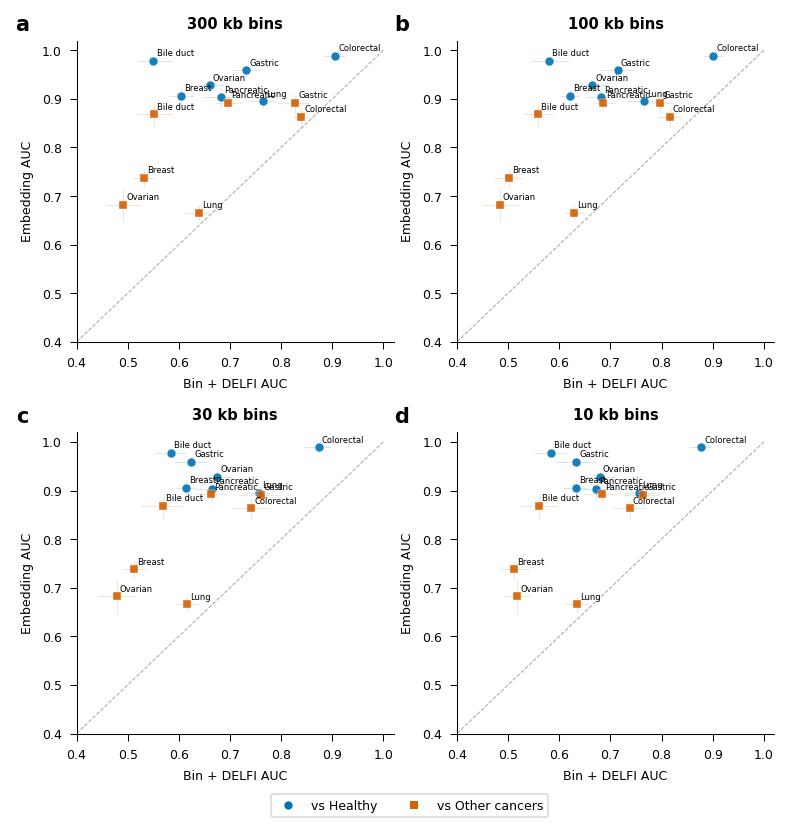

In [6]:
# =============================================================================
# SUPP FIG 11: Embedding AUC (y) vs Bin + DELFI AUC (x) at 100K fragments
# 4 panels = 4 n_bins resolutions. Blue circle = vs Healthy, orange square = vs Other.
# Error bars on both axes from ci_low/ci_high; dashed diagonal = parity.
# =============================================================================
BIN_METHOD = 'Binning (Bin + DELFI)'
BIN_SHORT = 'Bin + DELFI'
NBINS_GRID = [10000.0, 30000.0, 100000.0, 300000.0]
NBINS_GRID_LABELS = ['300 kb bins', '100 kb bins', '30 kb bins', '10 kb bins']

legend_handles = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=OKABE_ITO['blue'],
               markersize=5, label='vs Healthy'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=OKABE_ITO['orange'],
               markersize=5, label='vs Other cancers'),
]

fig = plt.figure(figsize=(6, 6))
gs = fig.add_gridspec(2, 2, hspace=0.3)

for panel_idx, (n_bins, nb_label) in enumerate(zip(NBINS_GRID, NBINS_GRID_LABELS)):
    ax = fig.add_subplot(gs[panel_idx // 2, panel_idx % 2])
    ax.plot([0.4, 1.0], [0.4, 1.0], color='#AAAAAA', linestyle='--',
            linewidth=0.5, zorder=1)

    for comparison, color, marker in [('vs_healthy', OKABE_ITO['blue'], 'o'),
                                      ('vs_other_cancers', OKABE_ITO['orange'], 's')]:
        emb_aucs, bin_aucs = [], []
        emb_ci_los, emb_ci_his = [], []
        bin_ci_los, bin_ci_his = [], []
        clabels = []
        for cancer, clabel in zip(CANCERS, CANCER_LABELS):
            task = f'{cancer}_cancer_{comparison}'
            emb = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == 'Embedding (mod_fragment1)') &
                          (df_base['sample_size'] == 100000)]
            bsub = df_base[(df_base['cancer'] == task) &
                           (df_base['config'] == BIN_METHOD) &
                           (df_base['n_bins'] == n_bins) &
                           (df_base['sample_size'] == 100000)]
            if emb.empty or bsub.empty:
                continue
            emb_aucs.append(emb['auc_mean'].values[0])
            emb_ci_los.append(emb['ci_low'].values[0])
            emb_ci_his.append(emb['ci_high'].values[0])
            bin_aucs.append(bsub['auc_mean'].values[0])
            bin_ci_los.append(bsub['ci_low'].values[0])
            bin_ci_his.append(bsub['ci_high'].values[0])
            clabels.append(clabel)

        emb_aucs = np.array(emb_aucs); bin_aucs = np.array(bin_aucs)
        ax.errorbar(bin_aucs, emb_aucs,
                    xerr=[bin_aucs - np.array(bin_ci_los), np.array(bin_ci_his) - bin_aucs],
                    yerr=[emb_aucs - np.array(emb_ci_los), np.array(emb_ci_his) - emb_aucs],
                    fmt='none', ecolor=color, alpha=0.2, elinewidth=0.4, zorder=2)
        ax.scatter(bin_aucs, emb_aucs, c=color, s=18, alpha=0.9, marker=marker,
                   edgecolors='white', linewidth=0.2, zorder=3)
        for ba, ea, cl in zip(bin_aucs, emb_aucs, clabels):
            ax.annotate(cl, (ba, ea), fontsize=4, ha='left', va='bottom',
                        xytext=(1.5, 1.5), textcoords='offset points')

    ax.set_xlim(0.4, 1.02)
    ax.set_ylim(0.4, 1.02)
    ax.set_xticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_yticks([0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    ax.set_title(nb_label, fontsize=7, fontweight='bold')
    ax.set_ylabel('Embedding AUC', fontsize=6)
    ax.set_xlabel(f'{BIN_SHORT} AUC', fontsize=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.text(-0.15, 1.02, 'abcd'[panel_idx], transform=ax.transAxes,
            fontsize=10, fontweight='bold', va='bottom', ha='right')

fig.axes[2].legend(handles=legend_handles, loc='upper center',
                   bbox_to_anchor=(1.05, -0.18), ncol=2, frameon=True,
                   fontsize=6, facecolor='white', edgecolor='#DDDDDD', framealpha=0.9)

savefig(fig, OUT, 'cfdna_emb_vs_bindelfi', data=(df_base[(df_base['config']==BIN_METHOD) & (df_base['sample_size']==100000) & (df_base['n_bins'].isin(NBINS_GRID))][['cancer','n_bins','auc_mean','ci_low','ci_high']].drop_duplicates(['cancer','n_bins']).rename(columns={'auc_mean':'bin_auc','ci_low':'bin_ci_low','ci_high':'bin_ci_high'}).merge(df_base[(df_base['config']=='Embedding (mod_fragment1)') & (df_base['sample_size']==100000)][['cancer','auc_mean','ci_low','ci_high']].drop_duplicates('cancer').rename(columns={'auc_mean':'emb_auc','ci_low':'emb_ci_low','ci_high':'emb_ci_high'}), on='cancer', how='inner')))
plt.show()

saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_healthy.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_healthy.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_healthy.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_healthy.tsv


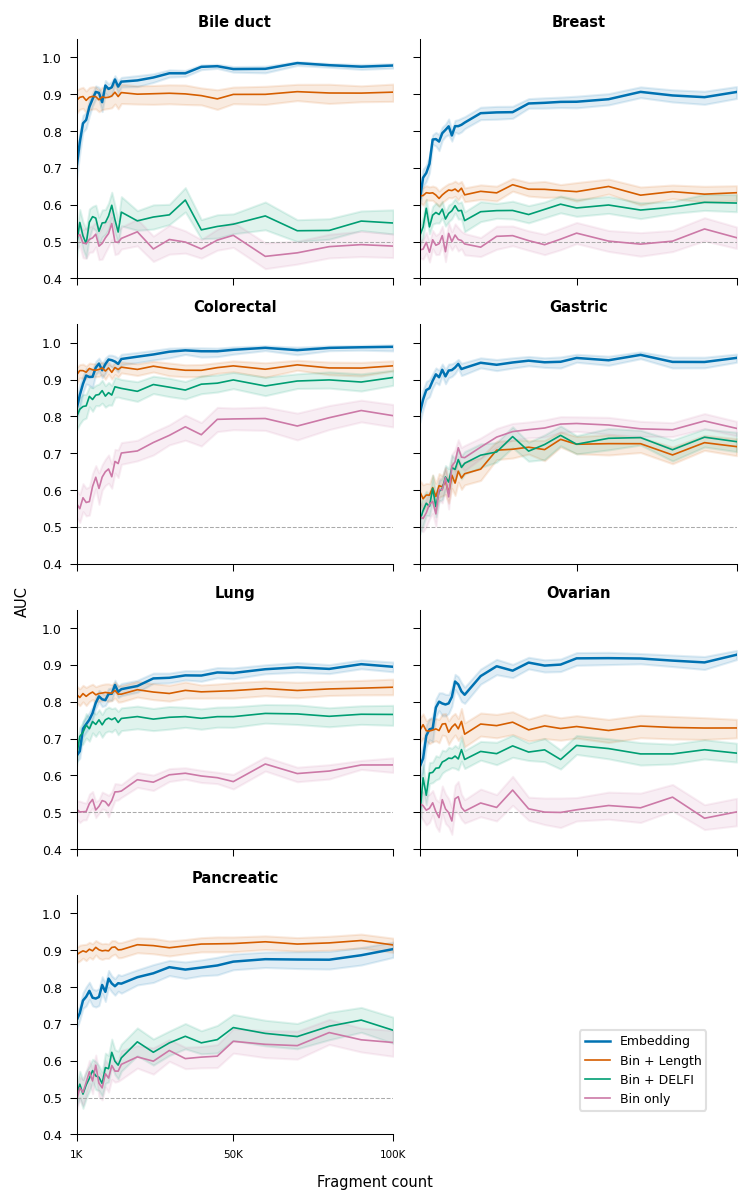

In [7]:
# =============================================================================
# SUPP FIG 12: Per-cancer subsampling curves -- cancer vs healthy
# 7 panels (one per cancer); AUC vs fragment count (linear x) for all 4 methods.
# Binning curves use n_bins == CURVE_NBINS (representative resolution from source).
# =============================================================================
fig, axes = plt.subplots(4, 2, figsize=(5, 8), sharey=True, sharex=True)
axes_flat = axes.flatten()

for idx, (cancer, cancer_label) in enumerate(zip(CANCERS, CANCER_LABELS)):
    ax = axes_flat[idx]
    task = f'{cancer}_cancer_vs_healthy'

    for config in CONFIG_ORDER:
        if 'Binning' in config:
            sub = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == config) &
                          (df_base['n_bins'] == CURVE_NBINS) &
                          (df_base['sample_size'] >= 1000)].sort_values('sample_size')
        else:
            sub = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == config) &
                          (df_base['sample_size'] >= 1000)].sort_values('sample_size')
        if sub.empty:
            continue
        color = CONFIG_COLORS[config]
        lw = 1.2 if config.startswith('Embedding') else 0.8
        ax.fill_between(sub['sample_size'], sub['ci_low'], sub['ci_high'],
                        color=color, alpha=0.12)
        ax.plot(sub['sample_size'], sub['auc_mean'], color=color, linewidth=lw)

    ax.axhline(0.5, color='#AAAAAA', linestyle='--', linewidth=0.5, zorder=1)
    ax.set_xlim(1000, 100000)
    ax.set_ylim(0.4, 1.05)
    ax.set_title(cancer_label, fontsize=7, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([1000, 50000, 100000])
    ax.set_xticklabels(['1K', '50K', '100K'], fontsize=5)
    ax.minorticks_off()

# Hide unused 8th panel
axes_flat[7].set_visible(False)

fig.supylabel('AUC', fontsize=7, x=0.02)
fig.supxlabel('Fragment count', fontsize=7)

legend_handles = [plt.Line2D([0], [0], color=CONFIG_COLORS[c],
                             linewidth=1.2 if 'Embedding' in c else 0.8,
                             label=CONFIG_LABELS[c]) for c in CONFIG_ORDER]
fig.legend(handles=legend_handles, loc='lower right', ncol=1, frameon=True,
           fontsize=6, facecolor='white', edgecolor='#DDDDDD', framealpha=0.9,
           bbox_to_anchor=(0.95, 0.07))

plt.tight_layout()
savefig(fig, OUT, 'cfdna_subsampling_vs_healthy', data=(df_base[df_base['cancer'].isin([f'{c}_cancer_vs_healthy' for c in CANCERS]) & df_base['config'].isin(CONFIG_ORDER) & (df_base['sample_size']>=1000) & ((df_base['config']=='Embedding (mod_fragment1)') | (df_base['n_bins']==CURVE_NBINS))][['cancer','config','n_bins','sample_size','auc_mean','ci_low','ci_high']].sort_values(['cancer','config','sample_size'])))
plt.show()

saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_other.pdf
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_other.png
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_other.svg
saved: /home/jingz/leaf-1-figures/cfdna/output/cfdna_subsampling_vs_other.tsv


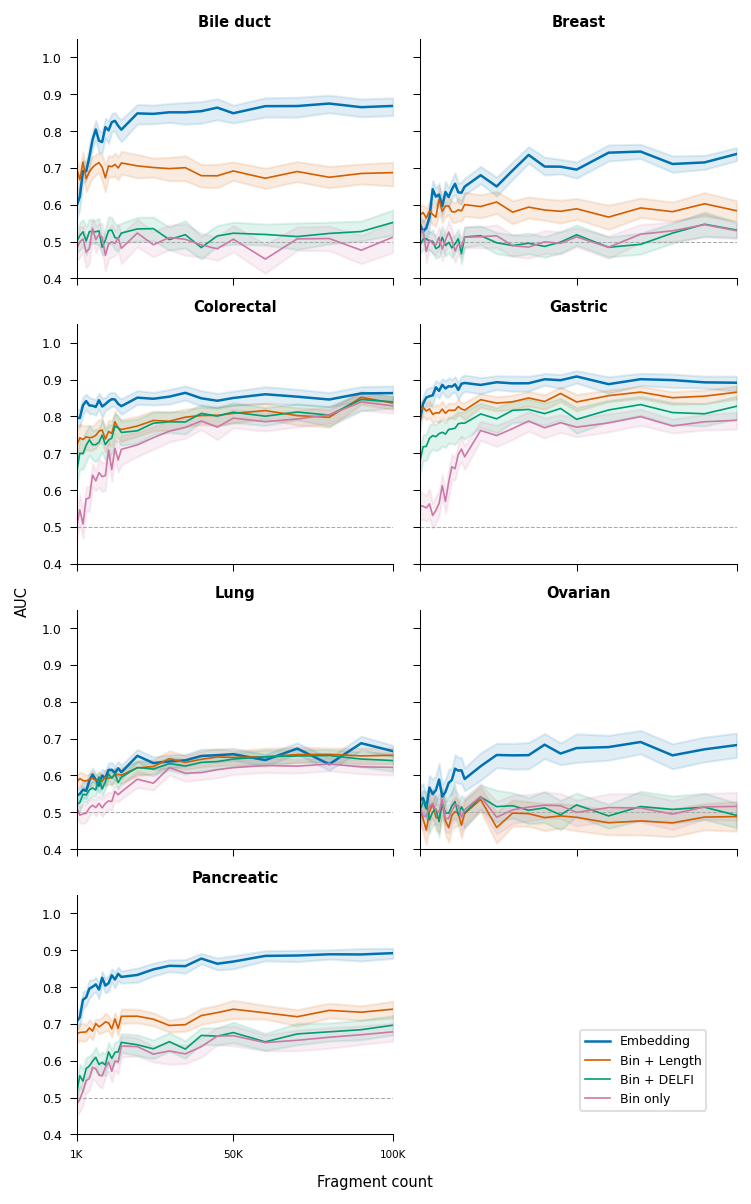

In [8]:
# =============================================================================
# SUPP FIG 13: Per-cancer subsampling curves -- cancer vs other cancers
# 7 panels (one per cancer); AUC vs fragment count (linear x) for all 4 methods.
# Binning curves use n_bins == CURVE_NBINS (representative resolution from source).
# =============================================================================
fig, axes = plt.subplots(4, 2, figsize=(5, 8), sharey=True, sharex=True)
axes_flat = axes.flatten()

for idx, (cancer, cancer_label) in enumerate(zip(CANCERS, CANCER_LABELS)):
    ax = axes_flat[idx]
    task = f'{cancer}_cancer_vs_other_cancers'

    for config in CONFIG_ORDER:
        if 'Binning' in config:
            sub = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == config) &
                          (df_base['n_bins'] == CURVE_NBINS) &
                          (df_base['sample_size'] >= 1000)].sort_values('sample_size')
        else:
            sub = df_base[(df_base['cancer'] == task) &
                          (df_base['config'] == config) &
                          (df_base['sample_size'] >= 1000)].sort_values('sample_size')
        if sub.empty:
            continue
        color = CONFIG_COLORS[config]
        lw = 1.2 if config.startswith('Embedding') else 0.8
        ax.fill_between(sub['sample_size'], sub['ci_low'], sub['ci_high'],
                        color=color, alpha=0.12)
        ax.plot(sub['sample_size'], sub['auc_mean'], color=color, linewidth=lw)

    ax.axhline(0.5, color='#AAAAAA', linestyle='--', linewidth=0.5, zorder=1)
    ax.set_xlim(1000, 100000)
    ax.set_ylim(0.4, 1.05)
    ax.set_title(cancer_label, fontsize=7, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.set_xticks([1000, 50000, 100000])
    ax.set_xticklabels(['1K', '50K', '100K'], fontsize=5)
    ax.minorticks_off()

# Hide unused 8th panel
axes_flat[7].set_visible(False)

fig.supylabel('AUC', fontsize=7, x=0.02)
fig.supxlabel('Fragment count', fontsize=7)

legend_handles = [plt.Line2D([0], [0], color=CONFIG_COLORS[c],
                             linewidth=1.2 if 'Embedding' in c else 0.8,
                             label=CONFIG_LABELS[c]) for c in CONFIG_ORDER]
fig.legend(handles=legend_handles, loc='lower right', ncol=1, frameon=True,
           fontsize=6, facecolor='white', edgecolor='#DDDDDD', framealpha=0.9,
           bbox_to_anchor=(0.95, 0.07))

plt.tight_layout()
savefig(fig, OUT, 'cfdna_subsampling_vs_other', data=(df_base[df_base['cancer'].isin([f'{c}_cancer_vs_other_cancers' for c in CANCERS]) & df_base['config'].isin(CONFIG_ORDER) & (df_base['sample_size']>=1000) & ((df_base['config']=='Embedding (mod_fragment1)') | (df_base['n_bins']==CURVE_NBINS))][['cancer','config','n_bins','sample_size','auc_mean','ci_low','ci_high']].sort_values(['cancer','config','sample_size'])))
plt.show()